<a href="https://colab.research.google.com/github/rajdeviharini-ops/Car-Price-Prediction/blob/main/Car_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [ ]:
import os
print(os.listdir('/content'))

['.config', 'sample_data']


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving used_cars.csv to used_cars (2).csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import os
print(os.listdir('/content'))

['.config', 'used_cars (1).csv', 'used_cars (2).csv', 'used_cars.csv', 'sample_data']


In [ ]:
df = pd.read_csv('/content/used_cars (1).csv')
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [ ]:
df = df.drop_duplicates()

df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)

df['milage'] = df['milage'].replace('[mi.,]', '', regex=True).astype(float)

df.head()

<>:3: SyntaxWarning: invalid escape sequence '\$'
<>:3: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_3664/2546491410.py:3: SyntaxWarning: invalid escape sequence '\$'
  df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500.0
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3207, 6457)
Testing data: (802, 6457)


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [ ]:
model.fit(X_train, y_train)

print("Model Training Successfully Completed!")

ValueError: could not convert string to float: '$30,510'

In [ ]:
df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)

df['price'] = pd.to_numeric(df['price'], errors='coerce')

In [ ]:
df = df.dropna(subset=['price'])

In [ ]:
X = df.drop('price', axis=1)
y = df['price']

In [ ]:
X = pd.get_dummies(X, drop_first=True)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Successfully Completed!")

Model Training Successfully Completed!


In [ ]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[30246.88273615 10715.40159303 43393.70826111 41292.04616896
 63330.76851082 35080.67685412 21732.17383289 28122.05192478
 23365.38911237 17139.85423   ]


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("R2 Score:", r2_score(y_test, y_pred))

print("MAE:", mean_absolute_error(y_test, y_pred))

print("MSE:", mean_squared_error(y_test, y_pred))

R2 Score: 0.06685078829683133
MAE: 21267.299480932645
MSE: 19073169610.218624


In [ ]:
result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

result.head(10)

,Actual Price,Predicted Price
0,28000.0,30246.882736
1,5900.0,10715.401593
2,41000.0,43393.708261
3,40250.0,41292.046169
4,77999.0,63330.768511
5,35899.0,35080.676854
6,36000.0,21732.173833
7,47214.0,28122.051925
8,30900.0,23365.389112
9,11000.0,17139.854230


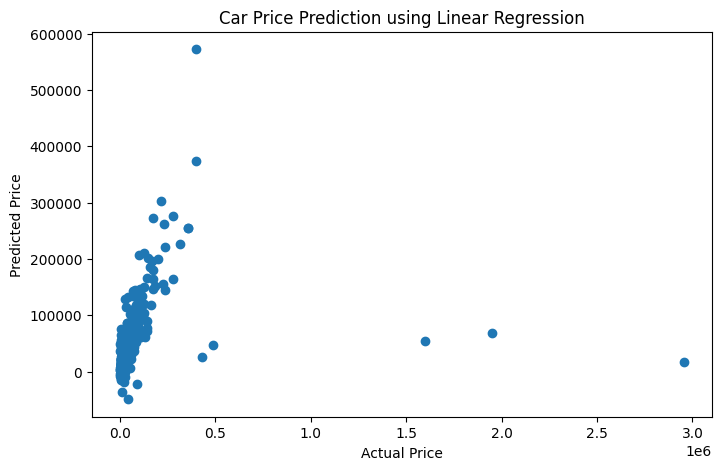

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Car Price Prediction using Linear Regression")

plt.show()

In [ ]:
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

R2 Score: 0.06685078829683133
MAE: 21267.299480932645


In [ ]:
result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(result.head(10))

   Actual Price  Predicted Price
0       28000.0     30246.882736
1        5900.0     10715.401593
2       41000.0     43393.708261
3       40250.0     41292.046169
4       77999.0     63330.768511
5       35899.0     35080.676854
6       36000.0     21732.173833
7       47214.0     28122.051925
8       30900.0     23365.389112
9       11000.0     17139.854230


In [ ]:
import joblib

joblib.dump(model, 'car_price_model.pkl')

print("Model Saved Successfully!")

Model Saved Successfully!


In [ ]:
from google.colab import files

files.download('car_price_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
sample_car = X_test.iloc[[0]]

predicted_price = model.predict(sample_car)

print("Predicted Car Price: $", round(predicted_price[0], 2))

Predicted Car Price: $ 30246.88
